# BUỔI 3 — Thực hành 2 (về nhà): Biến thể CNN
Dữ liệu: FashionMNIST (đổi `DATASET = 'cifar'` nếu muốn dùng CIFAR-10). Train 6.000 + validation 1.200 lấy từ official train, seed = 42. **Chọn mô hình chỉ dựa trên validation; test chính thức chỉ dùng một lần ở cuối.**

Các thí nghiệm (mỗi lần chỉ đổi 1 thuộc tính so với baseline): `baseline` · `kernel5` · `ch8` · `ch32` · `batchnorm` · `dropout0.3`.

In [1]:
import random, time
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

DATASET = 'fashion'  # 'fashion' hoặc 'cifar'
SEED, EPOCHS, BATCH_SIZE = 42, 5, 64
LR, TRAIN_SIZE, VAL_SIZE = 1e-3, 6000, 1200
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

CLASS_NAMES = (['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
                'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'] if DATASET == 'fashion' else
               ['airplane', 'automobile', 'bird', 'cat', 'deer',
                'dog', 'frog', 'horse', 'ship', 'truck'])

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def get_splits():
    cls = datasets.FashionMNIST if DATASET == 'fashion' else datasets.CIFAR10
    full = cls('./data', train=True, download=True, transform=transforms.ToTensor())
    ids = torch.randperm(len(full), generator=torch.Generator().manual_seed(SEED)).tolist()
    train_ds = Subset(full, ids[:TRAIN_SIZE])
    val_ds = Subset(full, ids[TRAIN_SIZE:TRAIN_SIZE + VAL_SIZE])
    return train_ds, val_ds, cls

def make_loaders(train_ds, val_ds):
    tr = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED), num_workers=0)
    va = DataLoader(val_ds, batch_size=256, num_workers=0)
    return tr, va

In [2]:
class CNN2Blocks(nn.Module):
    def __init__(self, in_channels=1, side=28, channels=16, kernel_size=3,
                 batchnorm=False, dropout=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, channels, kernel_size, padding=kernel_size//2)
        self.bn1 = nn.BatchNorm2d(channels) if batchnorm else nn.Identity()
        self.conv2 = nn.Conv2d(channels, 2*channels, kernel_size, padding=kernel_size//2)
        self.bn2 = nn.BatchNorm2d(2*channels) if batchnorm else nn.Identity()
        self.relu, self.pool = nn.ReLU(), nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(2*channels*(side//4)**2, 128)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.flatten(x)
        return self.fc2(self.drop(self.relu(self.fc1(x))))

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item()*x.size(0); n += x.size(0)
    return total/n

@torch.inference_mode()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, count = 0., 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss_sum += criterion(logits, y).item()*x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        count += x.size(0)
    return loss_sum/count, correct/count

## TODO 1 — Danh sách cấu hình (mỗi lần chỉ đổi 1 thuộc tính so với baseline)

In [3]:
def experiments():
    return [
        dict(name='baseline',   channels=16, kernel_size=3, batchnorm=False, dropout=0.0),
        dict(name='kernel5',    channels=16, kernel_size=5, batchnorm=False, dropout=0.0),
        dict(name='ch8',        channels=8,  kernel_size=3, batchnorm=False, dropout=0.0),
        dict(name='ch32',       channels=32, kernel_size=3, batchnorm=False, dropout=0.0),
        dict(name='batchnorm',  channels=16, kernel_size=3, batchnorm=True,  dropout=0.0),
        dict(name='dropout0.3', channels=16, kernel_size=3, batchnorm=False, dropout=0.3),
    ]

## Huấn luyện tất cả cấu hình (cùng seed, split, optimizer, lr, batch, epochs)

In [4]:
set_seed()
train_ds, val_ds, dataset_cls = get_splits()
in_channels, side = (1, 28) if DATASET == 'fashion' else (3, 32)
print('DEVICE:', DEVICE, '| DATASET:', DATASET)

rows, models = [], {}
for config in experiments():
    set_seed()
    model = CNN2Blocks(in_channels, side, config['channels'], config['kernel_size'],
                       config['batchnorm'], config['dropout']).to(DEVICE)
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    train_loader, val_loader = make_loaders(train_ds, val_ds)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()
    print('\n' + config['name'], f'| trainable_params={params}')
    history = []
    for epoch in range(1, EPOCHS + 1):
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
        history.append((epoch, train_loss, val_loss, val_acc, elapsed))
        print(f'Epoch={epoch}, train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, '
              f'val_acc={val_acc:.2%}, time={elapsed:.2f}s')
    rows.append((config, history, params))
    models[config['name']] = model

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 273kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.03MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.1MB/s]


DEVICE: cpu | DATASET: fashion

baseline | trainable_params=206922
Epoch=1, train_loss=1.1296, val_loss=0.6584, val_acc=76.92%, time=3.70s
Epoch=2, train_loss=0.6475, val_loss=0.5764, val_acc=78.92%, time=6.08s
Epoch=3, train_loss=0.5501, val_loss=0.4882, val_acc=81.75%, time=3.50s
Epoch=4, train_loss=0.4976, val_loss=0.4835, val_acc=82.42%, time=3.18s
Epoch=5, train_loss=0.4611, val_loss=0.4288, val_acc=86.25%, time=3.02s

kernel5 | trainable_params=215370
Epoch=1, train_loss=1.0544, val_loss=0.5944, val_acc=78.92%, time=4.55s
Epoch=2, train_loss=0.5901, val_loss=0.5075, val_acc=81.58%, time=4.25s
Epoch=3, train_loss=0.4928, val_loss=0.4628, val_acc=84.58%, time=4.73s
Epoch=4, train_loss=0.4423, val_loss=0.4375, val_acc=84.58%, time=4.32s
Epoch=5, train_loss=0.3996, val_loss=0.3992, val_acc=86.00%, time=4.10s

ch8 | trainable_params=103018
Epoch=1, train_loss=1.2316, val_loss=0.7160, val_acc=73.08%, time=1.93s
Epoch=2, train_loss=0.7038, val_loss=0.6112, val_acc=78.42%, time=2.49s
Epo

**Nhận xét:**
- Cả 6 cấu hình đều giảm loss đều qua 5 epoch, chưa có dấu hiệu overfit.
- `batchnorm` học nhanh nhất: epoch 1 đã đạt 85,42% (baseline chỉ 76,92%). Val loss của nó dao động ở epoch 2 (0,5035) rồi giảm lại.
- `dropout0.3` và `ch8` học chậm hơn baseline ở các epoch đầu.

## TODO 2 — Bảng so sánh

In [5]:
print(f"{'Cấu hình':<12}{'Tham số':>10}{'Train loss':>12}{'Val loss':>10}{'Val acc':>10}{'Giây/epoch':>12}")
print('-' * 66)
for cfg, h, params in rows:
    last = h[-1]
    print(f"{cfg['name']:<12}{params:>10,}{last[1]:>12.4f}{last[2]:>10.4f}{last[3]:>10.2%}"
          f"{np.mean([e[4] for e in h]):>12.2f}")

Cấu hình       Tham số  Train loss  Val loss   Val acc  Giây/epoch
------------------------------------------------------------------
baseline       206,922      0.4611    0.4288    86.25%        3.90
kernel5        215,370      0.3996    0.3992    86.00%        4.39
ch8            103,018      0.5144    0.4645    83.42%        2.17
ch32           421,642      0.3777    0.3814    86.33%        6.37
batchnorm      207,018      0.2723    0.3204    87.75%        3.66
dropout0.3     206,922      0.5193    0.4455    84.25%        3.23


**Nhận xét:**
- **Kernel 3→5:** thêm ~8 nghìn tham số, chậm hơn ~13%. Accuracy gần như không đổi (86,00% so với 86,25%) nhưng val loss thấp hơn (0,3992 so với 0,4288), nghĩa là dự đoán tự tin và chính xác hơn một chút.
- **Số kênh:** giảm xuống 8 kênh thì mô hình nhỏ đi một nửa và nhanh hơn, nhưng yếu hơn (83,42%, val loss 0,4645) vì ít bộ lọc để học đặc trưng. Tăng lên 32 kênh thì tham số gấp đôi, chậm gần gấp đôi, val loss tốt hơn (0,3814) nhưng accuracy chỉ ngang baseline (86,33%).
- **BatchNorm:** gần như không tốn thêm tham số (+96) và thời gian, nhưng cho kết quả tốt nhất (val acc 87,75%, val loss 0,3204, train loss 0,2723).
- **Dropout 0.3:** kém baseline (84,25%). Train loss còn cao (0,5193) nên mô hình đang underfit, dropout chưa cần thiết khi mới train 5 epoch trên 6.000 ảnh.
- Lưu ý: 1.200 mẫu validation nên chênh lệch dưới ~1 điểm % (khoảng 12 mẫu) chưa đủ để kết luận.

## TODO 2 — Learning curves

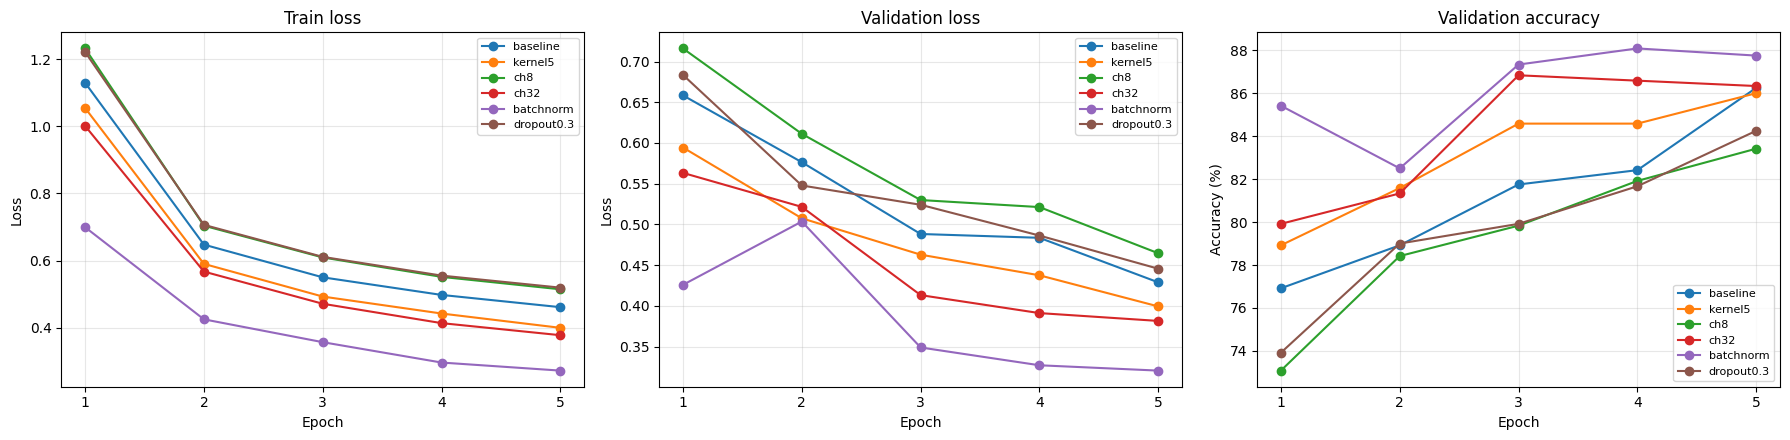

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ep = list(range(1, EPOCHS + 1))
for cfg, h, _ in rows:
    n = cfg['name']
    ax[0].plot(ep, [e[1] for e in h], '-o', label=n)
    ax[1].plot(ep, [e[2] for e in h], '-o', label=n)
    ax[2].plot(ep, [e[3] * 100 for e in h], '-o', label=n)
for a, t, y in zip(ax, ['Train loss', 'Validation loss', 'Validation accuracy'],
                   ['Loss', 'Loss', 'Accuracy (%)']):
    a.set(title=t, xlabel='Epoch', ylabel=y); a.set_xticks(ep); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('learning_curves.png', dpi=150); plt.show()

**Nhận xét:**
- Đường của `batchnorm` luôn nằm thấp nhất ở train loss và val loss (trừ epoch 2) và có val accuracy cao nhất ở hầu hết các epoch.
- `ch32` và `kernel5` nằm giữa; `ch8` và `dropout0.3` nằm cao nhất, tức học chậm nhất.
- Khoảng cách train–val của các mô hình đều nhỏ. `batchnorm` có khoảng cách lớn nhất (0,2723 so với 0,3204) vì nó giảm train loss nhanh hơn, nhưng val loss vẫn thấp nhất.

## TODO 3 — Chọn mô hình tốt nhất theo validation accuracy (hòa thì chọn validation loss thấp hơn)

In [7]:
best_cfg, best_hist, _ = max(rows, key=lambda r: (round(r[1][-1][3], 6), -r[1][-1][2]))
best_name = best_cfg['name']
print('Mô hình tốt nhất theo validation:', best_name,
      f"| val_acc={best_hist[-1][3]:.2%}, val_loss={best_hist[-1][2]:.4f}")
best_model = models[best_name]

Mô hình tốt nhất theo validation: batchnorm | val_acc=87.75%, val_loss=0.3204


**Nhận xét:** `batchnorm` được chọn nhờ val accuracy cao nhất (87,75%) và val loss thấp nhất (0,3204), hai tiêu chí cùng chỉ về một mô hình nên lựa chọn khá chắc chắn.

## TODO 4 — Đánh giá trên official test: accuracy và confusion matrix (hàng = nhãn thật, cột = nhãn dự đoán)

TEST (batchnorm): loss=0.3797, accuracy=86.81%


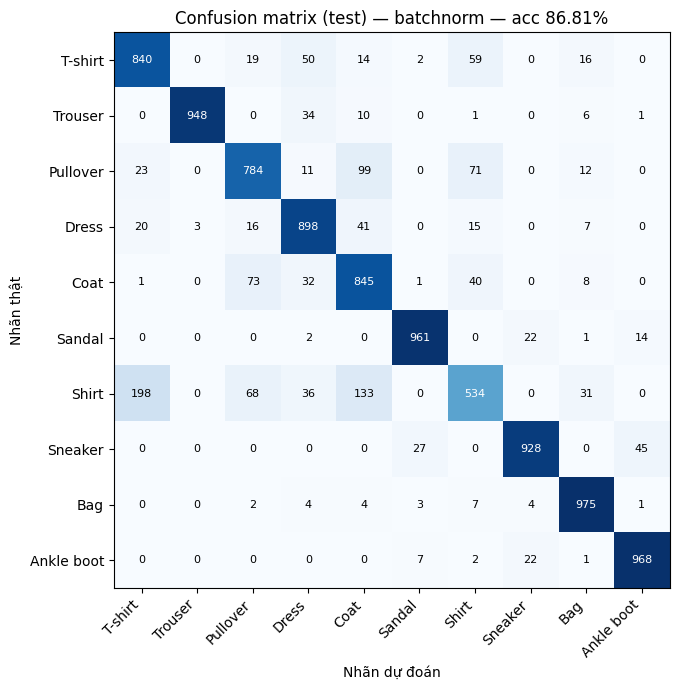

Nhầm nhiều: Shirt -> T-shirt: 198 mẫu
Nhầm nhiều: Shirt -> Coat: 133 mẫu
Nhầm nhiều: Pullover -> Coat: 99 mẫu


In [8]:
test_ds = dataset_cls('./data', train=False, download=True, transform=transforms.ToTensor())
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=0)
test_loss, test_acc = evaluate(best_model, test_loader, nn.CrossEntropyLoss())
print(f'TEST ({best_name}): loss={test_loss:.4f}, accuracy={test_acc:.2%}')

@torch.inference_mode()
def predict_all(model, loader):
    model.eval()
    xs, ys, ps = [], [], []
    for x, y in loader:
        ps.append(model(x.to(DEVICE)).argmax(1).cpu()); ys.append(y); xs.append(x)
    return torch.cat(xs), torch.cat(ys).numpy(), torch.cat(ps).numpy()

X_test, y_true, y_pred = predict_all(best_model, test_loader)
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(y_true, y_pred): cm[t, p] += 1

fig, a = plt.subplots(figsize=(8, 7))
a.imshow(cm, cmap='Blues')
a.set(title=f'Confusion matrix (test) — {best_name} — acc {test_acc:.2%}',
      xlabel='Nhãn dự đoán', ylabel='Nhãn thật', xticks=range(10), yticks=range(10))
a.set_xticklabels(CLASS_NAMES, rotation=45, ha='right'); a.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        a.text(j, i, cm[i, j], ha='center', va='center',
               color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=8)
plt.tight_layout(); plt.savefig('confusion_matrix_test.png', dpi=150); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
for i, j in np.dstack(np.unravel_index(np.argsort(-off.ravel())[:3], off.shape))[0]:
    print(f'Nhầm nhiều: {CLASS_NAMES[i]} -> {CLASS_NAMES[j]}: {off[i, j]} mẫu')

**Nhận xét:**
- Test accuracy là 86,81%, thấp hơn validation (87,75%) khoảng 1 điểm %. Test loss (0,3797) cũng cao hơn val loss (0,3204), điều bình thường vì mô hình được chọn dựa trên validation nên validation hơi lạc quan.
- Các lớp giày, túi, quần được nhận diện rất tốt (đa số trên 94%). Lớp yếu nhất là **Shirt**: chỉ 534/1000 ảnh đúng, hay bị nhầm thành T-shirt (198), Coat (133), Pullover (68).
- Các lỗi tập trung ở nhóm áo (Shirt, T-shirt, Pullover, Coat) và giữa Sneaker, Sandal, Ankle boot, vì hình dạng của chúng giống nhau.

## TODO 5 — 5 ảnh dự đoán đúng và 5 ảnh dự đoán sai trên test

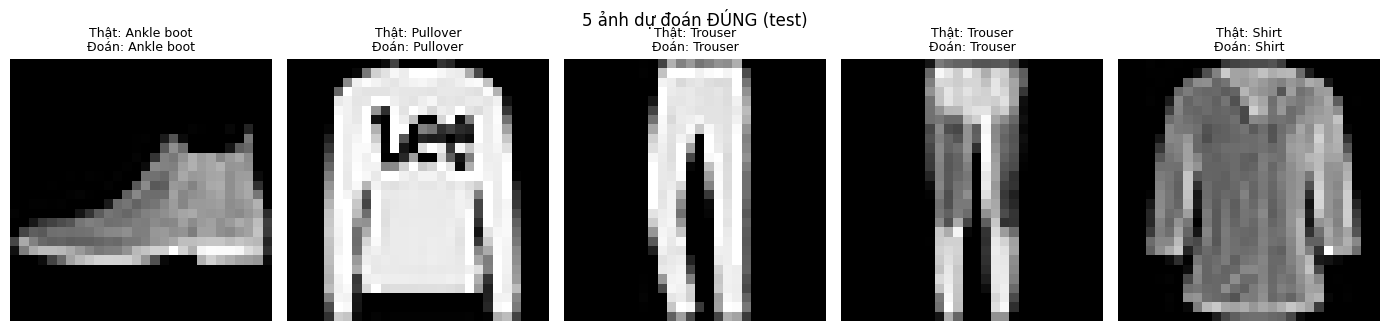

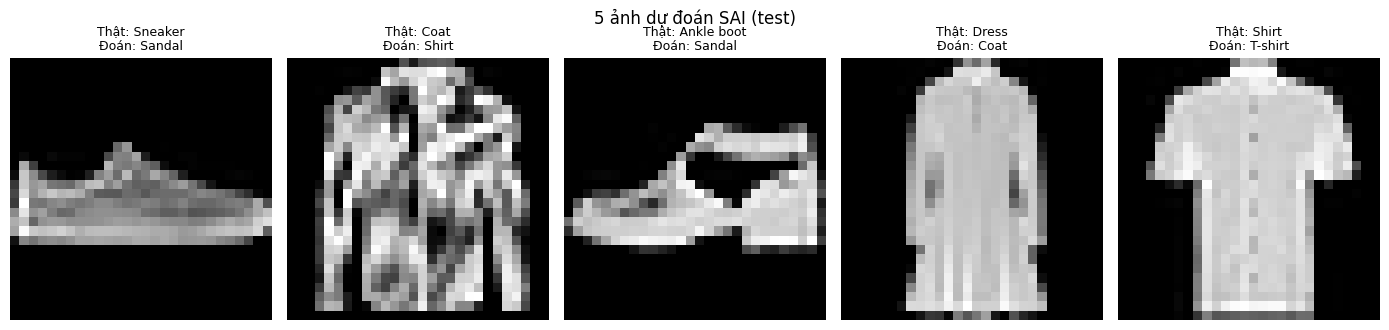

In [9]:
def show_images(idxs, title, fname):
    fig, axes = plt.subplots(1, 5, figsize=(14, 3.4))
    for a, k in zip(axes, idxs):
        img = X_test[k]
        a.imshow(img.squeeze(0), cmap='gray') if img.shape[0] == 1 else a.imshow(img.permute(1, 2, 0))
        a.set_title(f'Thật: {CLASS_NAMES[y_true[k]]}\nĐoán: {CLASS_NAMES[y_pred[k]]}', fontsize=9)
        a.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

correct_idx = np.where(y_true == y_pred)[0][:5]
wrong_idx = np.where(y_true != y_pred)[0][:5]
show_images(correct_idx, '5 ảnh dự đoán ĐÚNG (test)', 'five_correct.png')
show_images(wrong_idx, '5 ảnh dự đoán SAI (test)', 'five_wrong.png')

**Nhận xét:** các ảnh sai đều là những cặp lớp dễ nhầm: Coat đoán thành Shirt, Shirt đoán thành T-shirt, Dress đoán thành Coat, giày dép nhầm giữa Sneaker, Sandal và Ankle boot. Ảnh có độ phân giải 28×28 nên các chi tiết phân biệt (cổ áo, khuy, dây giày) rất nhỏ, ngay cả người nhìn cũng khó chắc chắn.

## TODO 6 — Nhận xét tổng hợp
1. **Kernel 3→5:** tăng nhẹ tham số và thời gian, accuracy không đổi rõ nhưng val loss tốt hơn.
2. **Số channel:** 8 kênh kém hơn baseline (83,42%) vì thiếu năng lực biểu diễn; 32 kênh tốt hơn về loss nhưng tốn gấp đôi tham số và thời gian mà accuracy chỉ ngang baseline, nên lợi ích không tương xứng chi phí.
3. **BatchNorm** là cải tiến hiệu quả nhất: hầu như không tốn thêm chi phí mà tăng val accuracy lên 87,75% (+1,5 điểm so với baseline) và hội tụ nhanh hơn. **Dropout 0.3** làm kết quả kém đi trong 5 epoch vì mô hình chưa overfit nên chưa cần chính quy hóa.
4. Mô hình `batchnorm` đạt **86,81%** trên official test, thấp hơn validation khoảng 1 điểm; lỗi chủ yếu ở lớp Shirt (nhầm với T-shirt, Coat, Pullover).
5. Lưu ý: mỗi cấu hình chỉ chạy 1 seed, 5 epoch, validation 1.200 mẫu, nên các chênh lệch nhỏ (dưới ~1 điểm %) chưa chắc chắn.